## 9.3-1 Neural Network Adaptive Controller

In [29]:
import numpy as np

# parameters
dt = 0.05
tfinal = 50.0
tswitch = 5.0
Mdelta = -10.0
Mq = -1.0
K = -1.0
gammaw = 1.0
gammav = 10
lam = 0.01
nmid = 5
nin = 3
amin = 0.01
amax = 10

In [ ]:
# precompute activation potentials
a = np.zeros((nmid, 1))
for i in range(nmid):
    a[i] = np.tan( np.atan(amin) + ( np.atan(amax) - np.atan(amin) ) * (i + 2)/nmid )
a

array([[ 0.67602117],
       [ 1.22624434],
       [ 2.41971997],
       [10.        ],
       [-5.12892395]])

In [21]:
# preallocate arrays
points = tfinal/dt + 1
t = np.zeros((int(points), 1))
r = np.zeros((int(points), 1))
x = np.zeros((int(points), 1))
u = np.zeros((int(points), 1))
w = np.zeros((int(points), nmid))
wdot = np.zeros((1, nmid))
v = np.zeros((int(points), nmid*nin))
vdot = np.zeros((1, nmid*nin))
rdot = np.zeros((1,1))
xdot = np.zeros((1,1))
Wdot = np.zeros((1,nmid))
W = np.zeros((1,nmid))
Vdot = np.zeros((nmid, nin))
V = np.zeros((nmid, nin))
xbar = np.zeros((nin,1))
sig = np.zeros((nmid,1))
sigp = np.zeros((nmid,nmid))

In [59]:
for i in range(int(points)):
    t[i] = i*dt

    # external input
    if int(np.floor(t[i].item())) > 0:
        if int(np.floor(t[i].item())) % int(2*tswitch) < int(tswitch):
            externalInput = 1.0
        else:
            externalInput = -1.0
    else:
        externalInput = 1.0

    # reference model
    rdot = -K*(externalInput - r[i])

    # error signals
    e = r[i] - x[i]
    e = e.reshape((1,1))

    # NN inputs
    if i > 0:
        oldu = u[i-1]
    else:
        oldu = 0.0
    xbar[0] = 1
    xbar[1] = x[i]
    xbar[2] = oldu

    # get weights from state vector
    W = w[i,:].reshape((1,-1))
    for j in range(nmid):
        V[j,:] = v[i,j*nin:(j+1)*nin]

    # adaptive control law
    vx = V @ xbar
    for j in range(nmid-1):
        ez = np.exp(-a[j]*vx[j])
        sig[j] = 1 / (1 + ez)
        sigp[j,j] = a[j].item()*ez.item()*sig[j].item()**2
    sig[nmid-1] = 1
    vad = W @ sig
    u[i] = ( rdot[0] - K*e - vad - Mq*x[i] ) / Mdelta

    # plant model
    xdot = np.sin(x[i]) + Mdelta*u[i] + Mq*x[i]

    # learning law
    Wdot = -gammaw * ( e @ (sig.T - xbar.T @ V.T @ sigp) + lam*np.linalg.norm(e) * W )
    Vdot = -gammav * ( sigp @ W.T @ e @ xbar.T + lam*np.linalg.norm(e) * V )

    # put NN update in a vector
    wdot = Wdot
    for j in range(nmid):
        vdot[:,j*nin:(j+1)*nin] = Vdot[j,:]
    
    # numerical integration
    if i == 0:
        x[i+1] = x[i] + dt*xdot
        r[i+1] = r[i] + dt*rdot
        w[i+1,:] = w[i,:] + dt*wdot
        v[i+1,:] = v[i,:] + dt*vdot
    elif i < points-1:
        x[i+1] = x[i] + ( 1.5*xdot - 0.5*oldxdot )*dt
        r[i+1] = r[i] + ( 1.5*rdot - 0.5*oldrdot )*dt
        w[i+1,:] = w[i,:] + ( 1.5*wdot - 0.5*oldwdot )*dt
        v[i+1,:] = v[i,:] + ( 1.5*vdot - 0.5*oldvdot )*dt

    oldxdot = xdot
    oldrdot = rdot
    oldwdot = wdot
    oldvdot = vdot

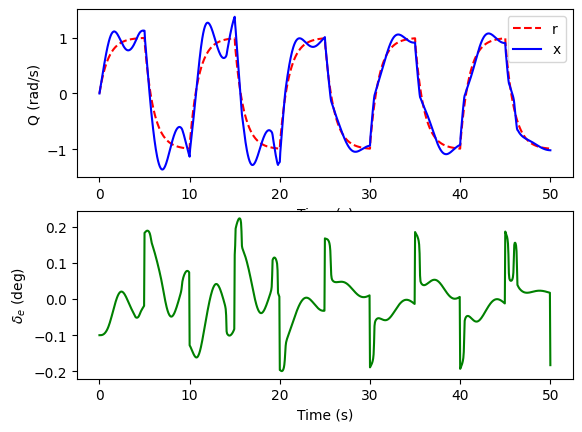

In [60]:
import matplotlib.pyplot as plt
plt.figure()
plt.subplot(2,1,1)
plt.plot(t, r, 'r--', label='r')
plt.plot(t, x, 'b-', label='x')
plt.legend()
plt.ylabel('Q (rad/s)')
plt.xlabel('Time (s)')
plt.subplot(2,1,2)
plt.plot(t, u, 'g-', label='u')
plt.ylabel('$\delta_e$ (deg)')
plt.xlabel('Time (s)')
plt.show()